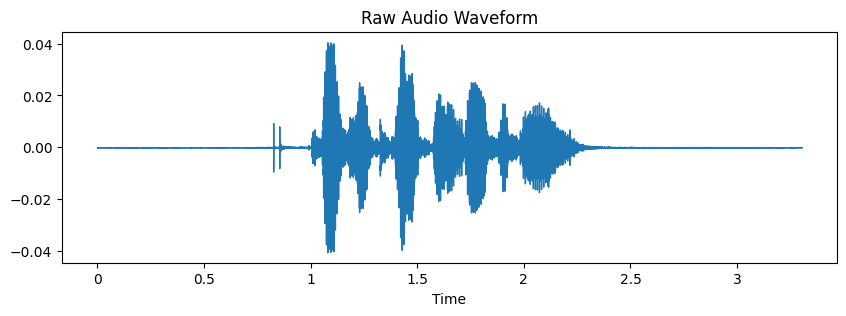

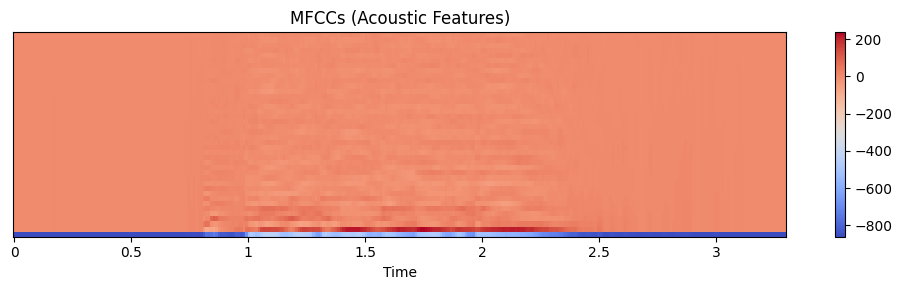

In [2]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# 1. Target a single audio file 
# UPDATE THIS PATH based on where you extracted the RAVDESS folders

file_path = "archive (1)/Actor_01/03-01-01-01-01-01-01.wav"
# Load the raw audio data (y) and the sampling rate (sr)
y, sr = librosa.load(file_path, sr=None) 

# 2. Extract MFCCs (These are the mathematical features the neural network will learn from)
mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)

# 3. Plot the Raw Waveform (Volume over time)
plt.figure(figsize=(10, 3))
librosa.display.waveshow(y, sr=sr)
plt.title("Raw Audio Waveform")
plt.show()

# 4. Plot the MFCC Heatmap (What the CNN will process as an image)
plt.figure(figsize=(10, 3))
librosa.display.specshow(mfccs, sr=sr, x_axis='time')
plt.colorbar()
plt.title("MFCCs (Acoustic Features)")
plt.tight_layout()
plt.show()

In [3]:
import os
import pandas as pd
import numpy as np
import librosa

# Path to your extracted dataset folder
data_path = "archive (1)"

all_features = []
all_labels = []

print("Starting feature extraction... This will take 1-2 minutes.")

# Loop through all actor directories
for actor_dir in os.listdir(data_path):
    actor_path = os.path.join(data_path, actor_dir)
    
    # Make sure we are only looking inside folders (like Actor_01)
    if os.path.isdir(actor_path):
        for file_name in os.listdir(actor_path):
            if file_name.endswith(".wav"):
                file_path = os.path.join(actor_path, file_name)
                
                # 1. Extract the emotion label from the filename digits
                # File name structure: 03-01-05-... -> 3rd digit (05) is the emotion
                parts = file_name.split('-')
                emotion_label = int(parts[2])
                
                # 2. Load audio and extract MFCCs
                try:
                    y, sr = librosa.load(file_path, sr=None)
                    # Get average MFCCs across time so every file matches size
                    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)
                    mfccs_processed = np.mean(mfccs.T, axis=0)
                    
                    all_features.append(mfccs_processed)
                    all_labels.append(emotion_label)
                except Exception as e:
                    print(f"Error processing {file_name}: {e}")

# Convert lists to NumPy arrays
X = np.array(all_features)
y = np.array(all_labels)

print(f"Extraction complete! Extracted {X.shape[0]} files.")
print(f"Features shape: {X.shape}, Labels shape: {y.shape}")

Starting feature extraction... This will take 1-2 minutes.
Extraction complete! Extracted 1440 files.
Features shape: (1440, 40), Labels shape: (1440,)


In [4]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv1D, MaxPooling1D, Flatten
import numpy as np

# 1. Adjust labels to start at 0 instead of 1 (Neural Networks count from 0)
# RAVDESS labels are 1-8. We make them 0-7.
y_adjusted = y - 1 

# 2. Split into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y_adjusted, test_size=0.2, random_state=42)

# 3. Reshape data for the CNN
# CNNs expect 3 dimensions: (number of files, features, channels)
X_train = np.expand_dims(X_train, axis=2)
X_test = np.expand_dims(X_test, axis=2)

# 4. Build the Neural Network Architecture
model = Sequential([
    # First Feature Extractor
    Conv1D(64, kernel_size=5, activation='relu', input_shape=(40, 1)),
    MaxPooling1D(pool_size=2),
    Dropout(0.2), # Dropout randomly turns off neurons to prevent the AI from just memorizing the data
    
    # Second Feature Extractor
    Conv1D(128, kernel_size=5, activation='relu'),
    MaxPooling1D(pool_size=2),
    Dropout(0.2),
    
    # Decision Layer
    Flatten(),
    Dense(128, activation='relu'),
    Dense(8, activation='softmax') # 8 output nodes representing the 8 distinct emotions
])

# 5. Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

print("Model architecture built! Starting the 50-epoch training process...")

# 6. Train the model (This will output a loading bar for each 'epoch' or study pass)
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_test, y_test))

# 7. Save the trained model to your hard drive
model.save("emotion_model.keras")
print("\nTraining complete! The 'brain' has been saved as 'emotion_model.keras'.")

Model architecture built! Starting the 50-epoch training process...
Epoch 1/50


c:\Users\ADMIN\Desktop\speech-emotion-recognition\venv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.1510 - loss: 3.4883 - val_accuracy: 0.1806 - val_loss: 2.0195
Epoch 2/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2118 - loss: 2.0673 - val_accuracy: 0.1944 - val_loss: 1.9305
Epoch 3/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2526 - loss: 1.9309 - val_accuracy: 0.3056 - val_loss: 1.8556
Epoch 4/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2656 - loss: 1.8714 - val_accuracy: 0.3299 - val_loss: 1.7969
Epoch 5/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3003 - loss: 1.7851 - val_accuracy: 0.3125 - val_loss: 1.7555
Epoch 6/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3351 - loss: 1.7489 - val_accuracy: 0.3090 - val_loss: 1.8204
Epoch 7/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3681 - loss: 1.6732 - val_accuracy: 0.4132 - val_loss: 1.6731
Epoch 8/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4132 - loss: 1.5967 - val_accuracy: 0.4340 - val_loss: 1.6075
Ep

In [5]:
import keras
import numpy as np
import librosa

# 1. Define the emotion dictionary mapping the numbers back to words
emotion_map = {
    0: "neutral",
    1: "calm",
    2: "happy",
    3: "sad",
    4: "angry",
    5: "fearful",
    6: "disgust",
    7: "surprised"
}

# 2. Load the saved neural network
loaded_model = keras.models.load_model("emotion_model.keras")
print("Model loaded successfully!")

# 3. Choose a single test file (Let's pick an angry file from Actor_02)
# File naming check: 03-01-05-... means 05 which is Angry (index 4)
test_file = "archive (1)/Actor_02/03-01-05-01-01-01-02.wav"

# 4. Process the test file exactly like training data
y, sr = librosa.load(test_file, sr=None)
mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)
mfccs_processed = np.mean(mfccs.T, axis=0)

# Reshape to match the 3D shape the CNN expects: (1 file, 40 features, 1 channel)
test_input = np.expand_dims(mfccs_processed, axis=0)
test_input = np.expand_dims(test_input, axis=2)

# 5. Run prediction
predictions = loaded_model.predict(test_input)
predicted_class = np.argmax(predictions)
predicted_emotion = emotion_map[predicted_class]

print(f"\nTarget True Emotion: angry")
print(f"AI Predicted Emotion: {predicted_emotion}")
print(f"Confidence Scores: {predictions[0]}")

Model loaded successfully!
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step

Target True Emotion: angry
AI Predicted Emotion: angry
Confidence Scores: [5.2597478e-02 1.8592151e-04 6.8739790e-04 1.4310175e-02 9.2648476e-01
 1.1596310e-04 4.7658072e-03 8.5244881e-04]
